# TDA : Clustering des diagrammes de persistance des scans 3D Caesar

#### Paramètres préliminaires

- Packages nécessaires

In [1]:
import utils
import os

np = utils.importer('numpy')
plt = utils.importer('matplotlib.pyplot')
pickle = utils.importer('pickle')
meshio = utils.importer('meshio')

In [2]:
pathglob = 'E:/TDA/Male/'
all_scans = os.listdir(pathglob)
nb_scans = len(all_scans)

In [3]:
all_scans[154]

'SPRING0330.obj'

- Fonction qui renvoie le nuage de points du scan

In [4]:
def scan_from_index(i):
    path = pathglob + str(all_scans[i])
    scan = meshio.read(path)
    scan = scan.points
    return scan

- On définit une fonction qui affichent le nuage de points associé à un scan 3D

In [5]:
def plot_scan_3D_interactive(i):
    scan = scan_from_index(i)
    points_set = utils.point_set(scan)
    points_set.plot(color='green', opacity=0.5, size=2)

### Diagrammes de persistance

- Paramètres de base

In [6]:
min_persistence = 3

* On importe les diagrammes et les diagrammes décolorés précédemment sauvegardés

In [7]:
with open ('./Data/XY.bin', 'rb') as fp:
    X = pickle.load(fp)

with open ('./Data/XY_decolor.bin', 'rb') as fp:
    X_decolor = pickle.load(fp)

### Distance entre les diagrammes (Wasserstein)

* On charge les distances, par homologie, précédemment calculées

In [8]:
with open ('./Data/XY_Dist_H0.bin', 'rb') as fp:
    dict_dist_0 = pickle.load(fp)
with open ('./Data/XY_Dist_H1.bin', 'rb') as fp:
    dict_dist_1 = pickle.load(fp)
with open ('./Data/XY_Dist_H2.bin', 'rb') as fp:
    dict_dist_2 = pickle.load(fp)

* On calcule les distances

In [9]:
dict_dist = {}
for key in dict_dist_1.keys():
    dict_dist[key] = np.sqrt(dict_dist_0[key] + dict_dist_1[key] + dict_dist_2[key])

* On choisit le degré d'homologie

In [10]:
d_d = dict_dist

- On affiche les distances maximum et minimum

In [11]:
max_key = max(d_d, key=d_d.get)
min_key = min(d_d, key=d_d.get)

print("max", max_key, d_d[max_key])
print("min", min_key, d_d[min_key])

max (266, 911) 21.830861190439915
min (833, 1200) 3.336605873744369


In [12]:
all_scans[46]

'SPRING0132.obj'

- On affiche les scans 3D des plus distants

In [13]:
plot_scan_3D_interactive(max_key[0])
plot_scan_3D_interactive(max_key[1])

- On affiche les scans 3D des plus proches

In [14]:
plot_scan_3D_interactive(min_key[0])
plot_scan_3D_interactive(min_key[1])

### Clustering hiérarchique

- On fait un clustering hiérarchique

In [15]:
dendrogram, linkage, fcluster = utils.importer(
    'scipy.cluster.hierarchy', 'dendrogram', 'linkage', 'fcluster')

plt.rcParams["figure.figsize"] = [15, 10]
plt.rcParams["figure.autolayout"] = True

# on peut utiliser single (min), complete (max), average (moyenne)
_, distances = zip(*sorted(d_d.items()))

In [16]:
Z = linkage(distances, metric='precomputed',
            method='complete', optimal_ordering=True)

- Voici le dendrogramme du clustering

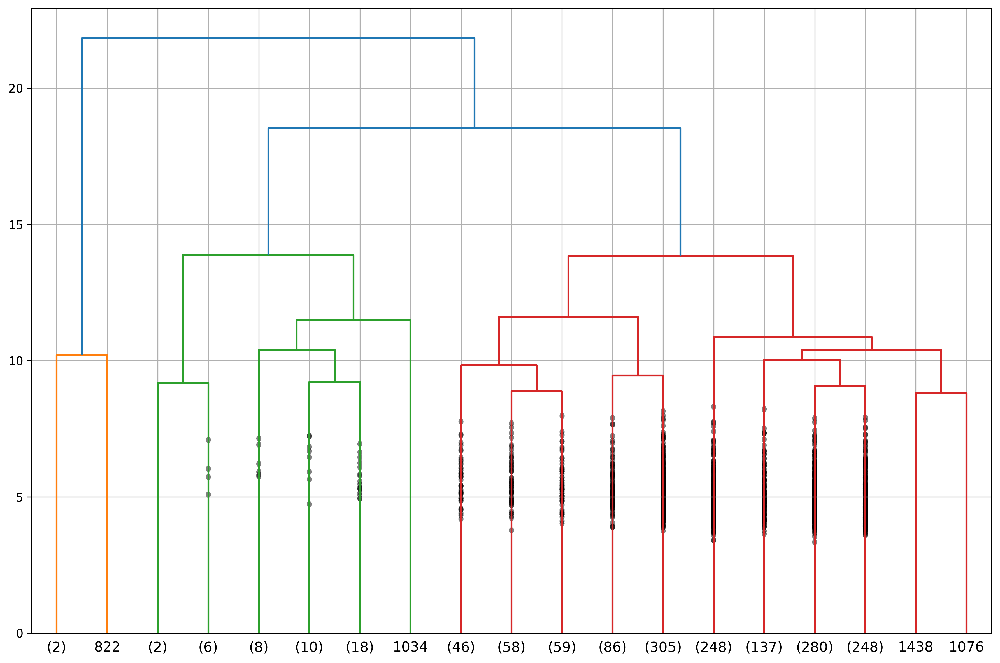

In [36]:
fig = plt.figure(figsize=(12, 8), dpi=300)
ax = fig.add_subplot(1, 1, 1)
# pour le nb d'individus par branche : show_contracted=True
dendrogram(Z, ax=ax, p=19, truncate_mode='lastp', show_contracted=True)
plt.grid(True)

### Courbe elbow du clustering

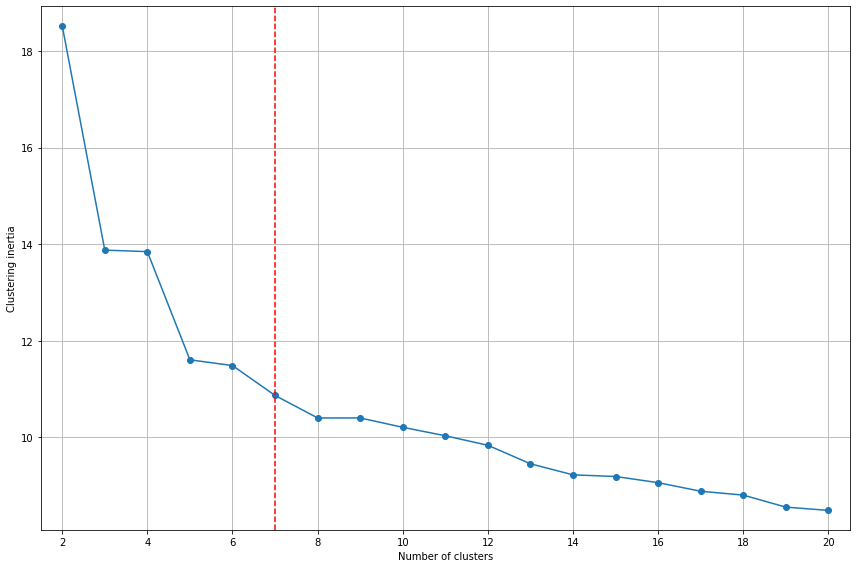

In [30]:
temp = 20  # nombre de clusters à afficher

fig = plt.figure(figsize=(12, 8))
ymin, ymax = np.min(Z[::-1, 2][1:temp]), np.max(Z[::-1, 2][1:temp])
a = (ymax - ymin) / 25

plt.plot(range(2, temp+1), Z[::-1, 2][1:temp], 'o-')
plt.plot([7, 7], [ymin-a, ymax+a], 'r--')
plt.ylim(ymin-a, ymax+a)
plt.xticks(range(2, 21, 2))
plt.xlim(1.5, 20.5)
plt.xlabel('Number of clusters')
plt.ylabel('Clustering inertia')
plt.tight_layout()
plt.grid(True)

- Voici la courbe associée à l'indice de Davies-Bouldin quand on fait varier le nombre de clusters

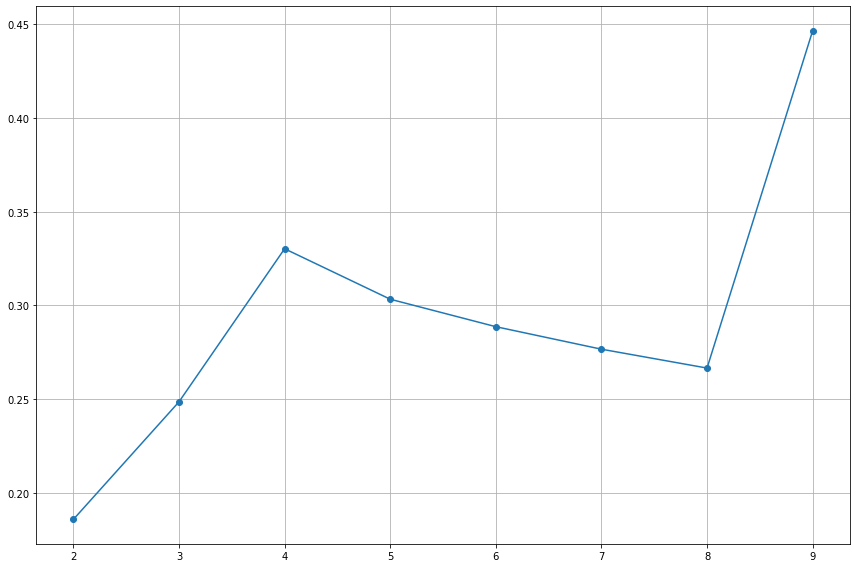

In [19]:
SDB_list = []
borne_nb_clus = 10

for i in range(2, borne_nb_clus):
    nb_clus = i

    clusters = fcluster(Z, nb_clus, criterion='maxclust')
    clusters = clusters.tolist()

    dict_clusters = {}
    for i in range(1, nb_clus+1):
        dict_clusters[i] = []
    for i in range(len(clusters)):
        dict_clusters[clusters[i]].append(i)
    SDB_list.append(utils.indice_DB(dict_clusters, d_d))

plt.figure(figsize=(12, 8))
plt.plot(range(2, borne_nb_clus), SDB_list, 'o-')
plt.grid(True);

- On choisit le nombre de clusters pour le clustering

In [31]:
nb_clus = 8  # À choisir
clusters = fcluster(Z, nb_clus, criterion='maxclust')

- Voici les individus par cluster

In [32]:
dict_clusters = {}
for i in range(1, nb_clus+1):
    dict_clusters[i] = []
for i in range(len(clusters)):
    dict_clusters[clusters[i]].append(i)

for key in dict_clusters:
    print('Cluster n°' + str(key), "de taille", len(
        dict_clusters[key]), ':', dict_clusters[key], '\n')

Cluster n°1 de taille 3 : [239, 266, 822] 

Cluster n°2 de taille 8 : [722, 798, 803, 968, 1023, 1061, 1074, 1387] 

Cluster n°3 de taille 36 : [0, 28, 40, 84, 145, 210, 229, 291, 306, 311, 319, 328, 329, 344, 433, 439, 494, 517, 519, 531, 553, 718, 740, 808, 877, 894, 908, 936, 973, 984, 1003, 1063, 1068, 1166, 1202, 1311] 

Cluster n°4 de taille 1 : [1034] 

Cluster n°5 de taille 163 : [22, 33, 44, 80, 99, 106, 113, 115, 133, 135, 165, 166, 180, 181, 186, 192, 193, 203, 211, 220, 222, 225, 245, 252, 253, 258, 267, 273, 277, 281, 290, 293, 304, 308, 309, 335, 341, 355, 379, 399, 406, 422, 438, 441, 450, 451, 452, 453, 454, 461, 468, 470, 487, 492, 493, 498, 500, 511, 514, 515, 518, 535, 559, 562, 570, 589, 593, 594, 602, 604, 607, 608, 612, 614, 618, 624, 633, 640, 648, 649, 652, 657, 658, 669, 675, 679, 684, 688, 697, 703, 710, 723, 725, 727, 730, 744, 751, 763, 777, 815, 820, 823, 824, 825, 841, 842, 843, 844, 851, 855, 863, 864, 872, 874, 879, 889, 924, 929, 932, 942, 943, 959, 966

In [22]:
all_scans[822]

'SPRING2277.obj'

### Centre des clusters

In [23]:
for i in dict_clusters:
    medoid = utils.cluster_medoid(dict_clusters[i], d_d)
    print("Le cluster", i, "est de longueur", str(len(
        dict_clusters[i]))+", son médoïde est l'individu", medoid, "et voici son scan")
    plot_scan_3D_interactive(medoid)

Le cluster 1 est de longueur 3, son médoïde est l'individu 239 et voici son scan


Le cluster 2 est de longueur 8, son médoïde est l'individu 1387 et voici son scan


Le cluster 3 est de longueur 37, son médoïde est l'individu 517 et voici son scan


Le cluster 4 est de longueur 554, son médoïde est l'individu 733 et voici son scan


Le cluster 5 est de longueur 915, son médoïde est l'individu 583 et voici son scan


In [24]:
for index in [239, 803, 553, 733, 63]:
    print(all_scans[index])

SPRING0517.obj
SPRING2175.obj
SPRING1502.obj
SPRING1878.obj
SPRING0154.obj


## K-Medoids

In [25]:
# KMedoids = utils.importer('sklearn_extra.cluster', 'KMedoids')

# distance = np.zeros((nb_scans, nb_scans))

# for i in range(nb_scans):
#     for j in range(i+1, nb_scans):
#         distance[i, j] = distance[j, i] = d_d[(i, j)]

In [26]:
# KElbowVisualizer = utils.importer('yellowbrick.cluster', 'KElbowVisualizer')

# model = KMedoids(method='pam')
# visualizer = KElbowVisualizer(model, k=(2, 16), timings=False)

# visualizer.fit(distance)   # Fit the data to the visualizer
# visualizer.show();         # Finalize and render the figure

In [27]:
# nb_clus = 8

# kmed = KMedoids(n_clusters=nb_clus, method='pam').fit(distance)
# clusters = kmed.labels_

In [28]:
# dict_clusters = {}
# for i in range(1, nb_clus+1):
#     dict_clusters[i] = []
# for i in range(len(clusters)):
#     dict_clusters[clusters[i]+1].append(i)

# for key in dict_clusters:
#     print('Cluster n°' + str(key), "de taille", len(
#         dict_clusters[key]), ':', dict_clusters[key], '\n')

In [29]:
# indices = kmed.medoid_indices_

# for i in range(indices.shape[0]):
#     medoid = indices[i]
#     print("Le cluster", i+1, "est de longueur", str(len(
#         dict_clusters[i+1]))+", son médoïde est l'individu", medoid, "et voici son scan")
#     plot_scan_3D_interactive(medoid)